In [1]:
# FinGuard - Notebook 04: Cost-Sensitive Business Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
# 1. Load
X_test = pd.read_csv('./data/processed/X_test.csv')
X_test_scaled = pd.read_csv('./data/processed/X_test_scaled.csv')
y_test = pd.read_csv('./data/processed/y_test.csv').squeeze()

with open('./models_saved/model_metadata.json') as f:
    meta = json.load(f)
with open('./models_saved/model_metrics.json') as f:
    metrics = json.load(f)

best_name = meta['best_model']
safe_name = best_name.lower().replace(' ', '_')
best_model = joblib.load(f'./models_saved/{safe_name}.pkl')

# Linear model হলে scaled data ব্যবহার করতে হবে
linear_models = ['Logistic Regression', 'SVM']
X_te = X_test_scaled if best_name in linear_models else X_test

threshold = float(metrics[best_name]['threshold'])
print(f"Best Model: {best_name}")
print(f"Threshold: {threshold:.4f}")

Best Model: Random Forest
Threshold: 0.8775


In [3]:
#   2. Predictions  
y_proba = best_model.predict_proba(X_te)[:, 1]
y_pred = (y_proba >= threshold).astype(int)

#   3. Confusion Matrix  
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("\n=== Confusion Matrix ===")
print(f"True Negatives:  {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}   <-- MISSED FRAUDS")
print(f"True Positives:  {tp:,}")

#   4. Cost-Sensitive Analysis  
# MFS context: 1টি fraud miss = ~50,000 BDT loss
#             1টি false positive = ~200 BDT customer service cost
#             ratio ≈ 250:1

print("\n=== Cost-Sensitive Analysis ===")
print(f"{'Cost Ratio':<15}{'Total Cost (BDT)':<20}{'vs Baseline':<15}")
print("-" * 50)
baseline = None
for ratio in [10, 50, 100, 250, 500]:
    total_cost = fn * ratio + fp * 1
    if baseline is None:
        baseline = total_cost
    improvement = (baseline - total_cost) / baseline * 100
    print(f"{ratio}:1{'':<11}{total_cost:>15,} {improvement:>+10.2f}%")


=== Confusion Matrix ===
True Negatives:  950,296
False Positives: 89
False Negatives: 2,257   <-- MISSED FRAUDS
True Positives:  1,751

=== Cost-Sensitive Analysis ===
Cost Ratio     Total Cost (BDT)    vs Baseline    
--------------------------------------------------
10:1                    22,659      +0.00%
50:1                   112,939    -398.43%
100:1                   225,789    -896.46%
250:1                   564,339   -2390.57%
500:1                 1,128,589   -4880.75%



💰 Cost-Optimal Threshold: 0.6732
💰 Minimum Cost: 384,013 BDT


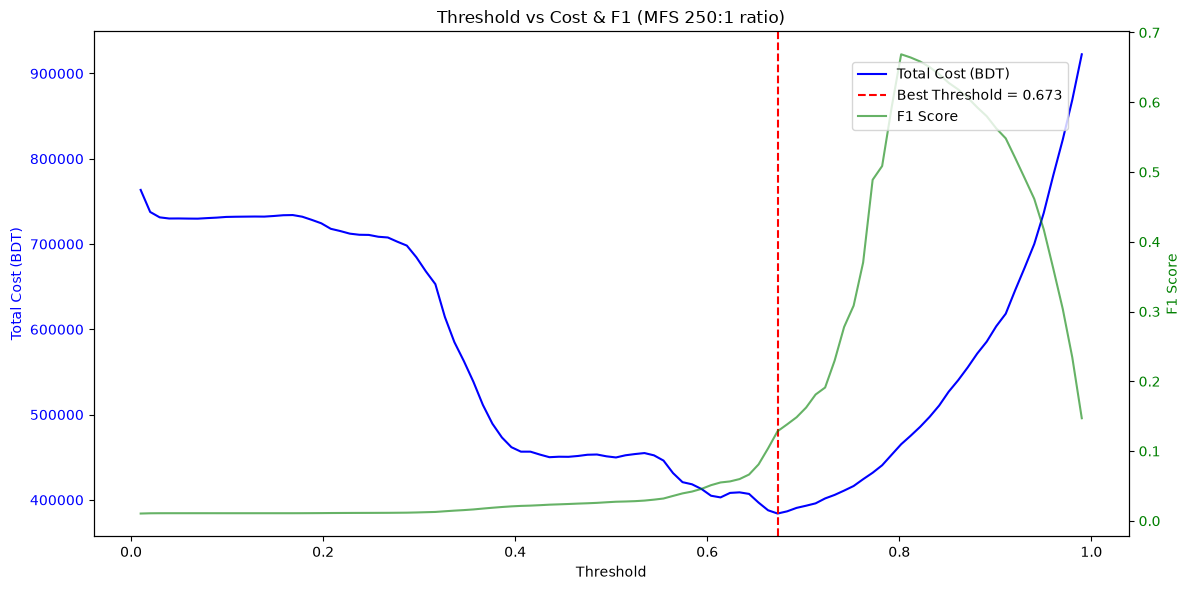

In [4]:
#   5. Threshold vs Cost Curve  
thresholds = np.linspace(0.01, 0.99, 100)
costs = []
f1s = []
for t in thresholds:
    yp = (y_proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, yp).ravel()
    costs.append(fn_t * 250 + fp_t * 1)   # MFS 250:1 ratio
    f1s.append(2*tp_t / (2*tp_t + fp_t + fn_t + 1e-10))

best_cost_idx = int(np.argmin(costs))
print(f"\n💰 Cost-Optimal Threshold: {thresholds[best_cost_idx]:.4f}")
print(f"💰 Minimum Cost: {costs[best_cost_idx]:,} BDT")

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(thresholds, costs, 'b-', label='Total Cost (BDT)')
ax1.axvline(thresholds[best_cost_idx], color='red', linestyle='--',
            label=f'Best Threshold = {thresholds[best_cost_idx]:.3f}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Total Cost (BDT)', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(thresholds, f1s, 'g-', alpha=0.6, label='F1 Score')
ax2.set_ylabel('F1 Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

plt.title('Threshold vs Cost & F1 (MFS 250:1 ratio)')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.savefig('./reports/figures/cost_threshold_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
#   6. Business Metrics  
print("\n=== Business Metrics ===")
print(f"Fraud Detection Rate:  {tp/(tp+fn)*100:.2f}%")
print(f"False Alarm Rate:      {fp/(fp+tn)*100:.6f}%")
print(f"Alert Precision:       {tp/(tp+fp)*100:.2f}%")
print(f"Total Frauds:          {tp+fn:,}")
print(f"Frauds Caught:         {tp:,}")
print(f"Frauds Missed:         {fn:,}")

#   7. Classification Report  
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred,
      target_names=['Non-Fraud', 'Fraud'], digits=4))


=== Business Metrics ===
Fraud Detection Rate:  43.69%
False Alarm Rate:      0.009365%
Alert Precision:       95.16%
Total Frauds:          4,008
Frauds Caught:         1,751
Frauds Missed:         2,257

=== Classification Report ===
              precision    recall  f1-score   support

   Non-Fraud     0.9976    0.9999    0.9988    950385
       Fraud     0.9516    0.4369    0.5988      4008

    accuracy                         0.9975    954393
   macro avg     0.9746    0.7184    0.7988    954393
weighted avg     0.9974    0.9975    0.9971    954393

